In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("tips")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [2]:
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

print("Categorical columns:")
print(categorical_columns.tolist())

for column in categorical_columns:
    print(f"{column}: {df[column].nunique()} unique categories")

Categorical columns:
['sex', 'smoker', 'day', 'time']
sex: 2 unique categories
smoker: 2 unique categories
day: 4 unique categories
time: 2 unique categories


## 1. Unique Categories

Unique categories are the distinct values present in a categorical variable. Identifying them helps us understand the possible groups represented in the dataset and detect inconsistent labels.

For example, the `day` column contains restaurant visit days, while the `smoker` column indicates whether a customer smokes.

In [3]:
for column in categorical_columns:
    print(f"\nUnique categories in '{column}':")
    print(df[column].unique())


Unique categories in 'sex':
['Female', 'Male']
Categories (2, str): ['Male', 'Female']

Unique categories in 'smoker':
['No', 'Yes']
Categories (2, str): ['Yes', 'No']

Unique categories in 'day':
['Sun', 'Sat', 'Thur', 'Fri']
Categories (4, str): ['Thur', 'Fri', 'Sat', 'Sun']

Unique categories in 'time':
['Dinner', 'Lunch']
Categories (2, str): ['Lunch', 'Dinner']


## 2. Category Frequencies

Category frequency is the number of observations belonging to each category. Frequency analysis helps identify common and uncommon categories in a dataset.

In [4]:
for column in categorical_columns:
    print(f"\nFrequency counts for '{column}':")
    display(df[column].value_counts(dropna=False))


Frequency counts for 'sex':


sex
Male      157
Female     87
Name: count, dtype: int64


Frequency counts for 'smoker':


smoker
No     151
Yes     93
Name: count, dtype: int64


Frequency counts for 'day':


day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64


Frequency counts for 'time':


time
Dinner    176
Lunch      68
Name: count, dtype: int64

## 3. Category Distribution

Category distribution describes how observations are spread across the categories of a variable. Percentages help compare categories even when datasets have different sizes.


Percentage distribution of 'sex':


,Percentage
sex,
Male,64.34
Female,35.66


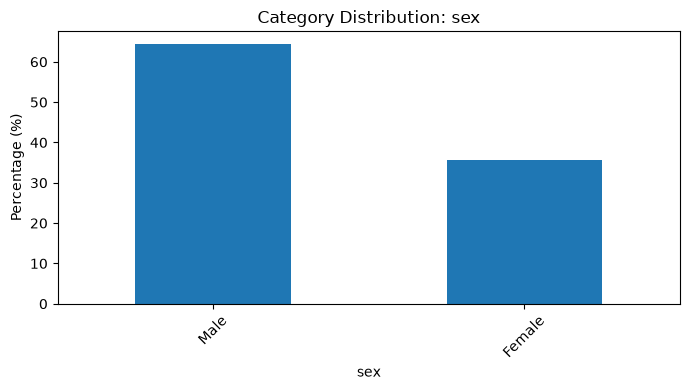


Percentage distribution of 'smoker':


,Percentage
smoker,
No,61.89
Yes,38.11


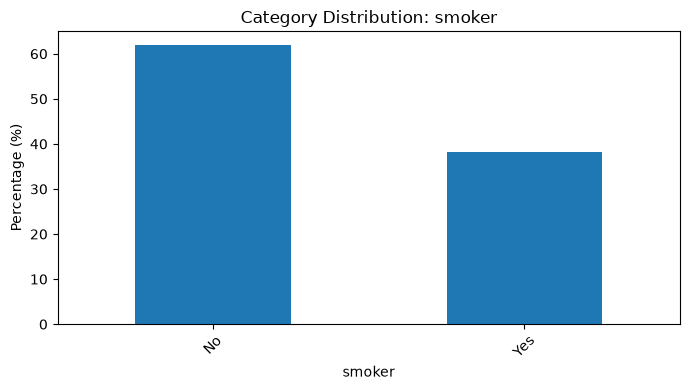


Percentage distribution of 'day':


,Percentage
day,
Sat,35.66
Sun,31.15
Thur,25.41
Fri,7.79


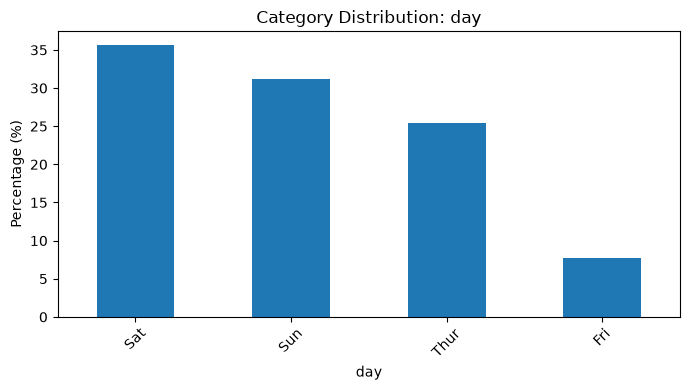


Percentage distribution of 'time':


,Percentage
time,
Dinner,72.13
Lunch,27.87


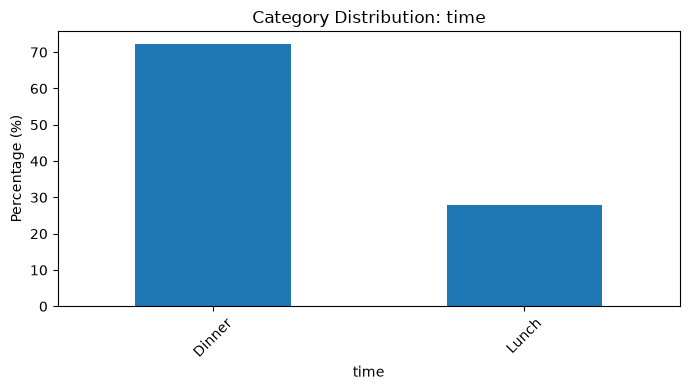

In [5]:
for column in categorical_columns:
    print(f"\nPercentage distribution of '{column}':")
    percentages = df[column].value_counts(
        normalize=True, dropna=False
    ) * 100

    display(percentages.round(2).to_frame("Percentage"))

    percentages.plot(kind="bar", figsize=(7, 4))
    plt.title(f"Category Distribution: {column}")
    plt.ylabel("Percentage (%)")
    plt.xlabel(column)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 4. Rare Categories

Rare categories are categories that appear only a small number of times. They may represent uncommon but valid observations, data-quality issues, or categories that require special treatment during data preprocessing.

In [6]:
rare_threshold = 5

for column in categorical_columns:
    counts = df[column].value_counts(dropna=False)
    rare_categories = counts[counts < rare_threshold]

    print(f"\nRare categories in '{column}' (fewer than {rare_threshold} observations):")
    if rare_categories.empty:
        print("No rare categories found.")
    else:
        display(rare_categories.to_frame("Count"))


Rare categories in 'sex' (fewer than 5 observations):
No rare categories found.

Rare categories in 'smoker' (fewer than 5 observations):
No rare categories found.

Rare categories in 'day' (fewer than 5 observations):
No rare categories found.

Rare categories in 'time' (fewer than 5 observations):
No rare categories found.


## 5. High and Low Cardinality

**Low cardinality** means a variable has relatively few distinct categories, such as `smoker` or `time`.

**High cardinality** means a variable has many distinct categories, such as customer IDs or postal codes. High-cardinality features may need special encoding strategies for machine learning.

In [7]:
cardinality = pd.DataFrame({
    "Feature": categorical_columns,
    "Unique Categories": [
        df[column].nunique(dropna=False)
        for column in categorical_columns
    ]
})

display(cardinality.sort_values(
    "Unique Categories", ascending=False
))

,Feature,Unique Categories
2,day,4
0,sex,2
1,smoker,2
3,time,2


## 6. Category Imbalance

Category imbalance occurs when observations are unevenly distributed across categories. A dominant category may influence analysis and machine learning results. The degree of imbalance should be assessed in context rather than assumed to be a problem.

In [8]:
for column in categorical_columns:
    counts = df[column].value_counts(dropna=False)

    print(f"\nCategory imbalance check for '{column}':")
    print("Most frequent category percentage:",
          round(counts.max() / counts.sum() * 100, 2), "%")

    display(counts.to_frame("Count"))


Category imbalance check for 'sex':
Most frequent category percentage: 64.34 %


,Count
sex,
Male,157
Female,87



Category imbalance check for 'smoker':
Most frequent category percentage: 61.89 %


,Count
smoker,
No,151
Yes,93



Category imbalance check for 'day':
Most frequent category percentage: 35.66 %


,Count
day,
Sat,87
Sun,76
Thur,62
Fri,19



Category imbalance check for 'time':
Most frequent category percentage: 72.13 %


,Count
time,
Dinner,176
Lunch,68


## 7. Relationships Between Categorical Variables and the Target

Analyzing categorical variables against a target variable helps identify differences between groups. For a numerical target, group means and box plots can show how the target varies across categories. These patterns describe associations and do not necessarily imply causation.


Average tip by sex:


,Average Tip
sex,
Male,3.09
Female,2.83


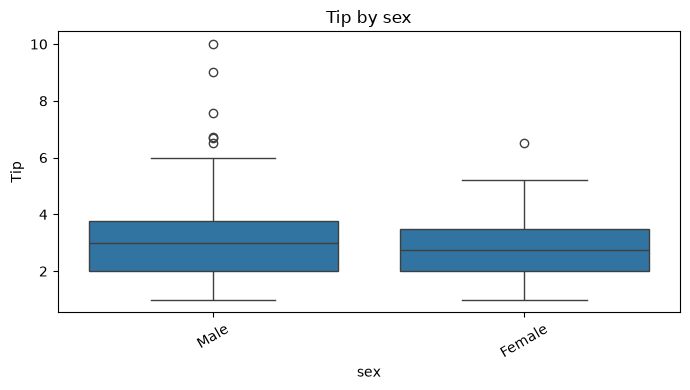


Average tip by smoker:


,Average Tip
smoker,
Yes,3.01
No,2.99


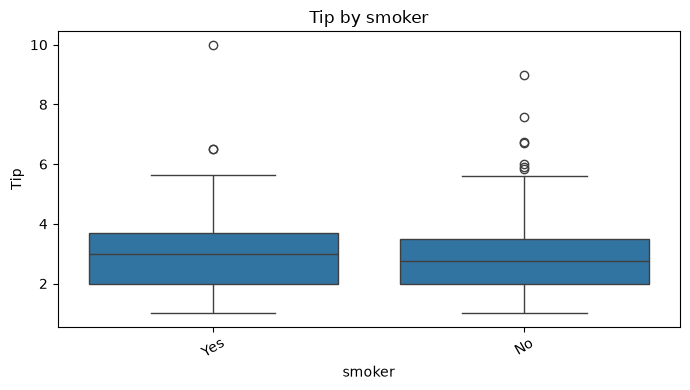


Average tip by day:


,Average Tip
day,
Thur,2.77
Fri,2.73
Sat,2.99
Sun,3.26


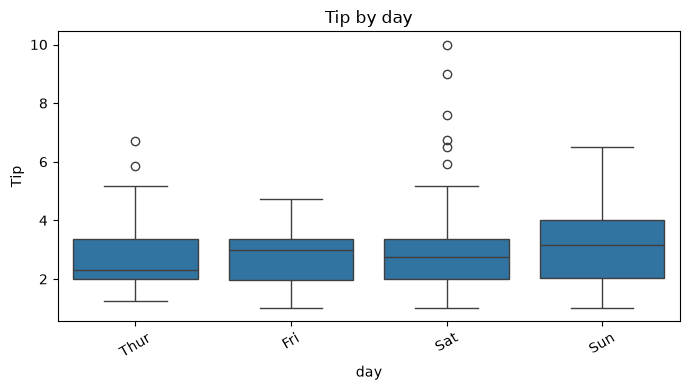


Average tip by time:


,Average Tip
time,
Lunch,2.73
Dinner,3.10


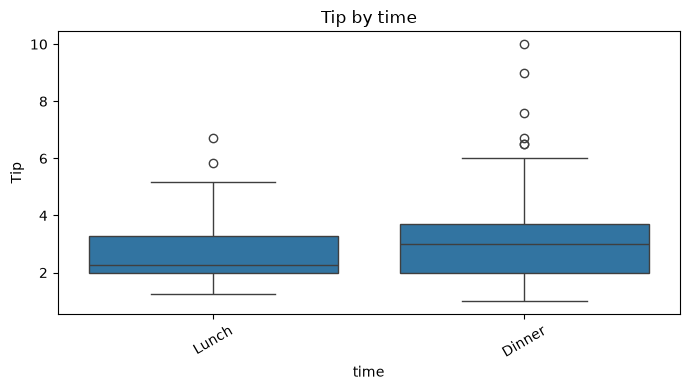

In [9]:
target_column = "tip"

for column in categorical_columns:
    print(f"\nAverage {target_column} by {column}:")
    display(
        df.groupby(column, observed=False)[target_column]
        .mean()
        .round(2)
        .to_frame("Average Tip")
    )

    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=column, y=target_column)
    plt.title(f"{target_column.title()} by {column}")
    plt.xlabel(column)
    plt.ylabel(target_column.title())
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [10]:
category_table = pd.crosstab(
    df["day"],
    df["smoker"],
    margins=True
)

print("Cross-tabulation: Day vs Smoker")
display(category_table)

Cross-tabulation: Day vs Smoker


smoker,Yes,No,All
day,,,
Thur,17,45,62
Fri,15,4,19
Sat,42,45,87
Sun,19,57,76
All,93,151,244


smoker,Yes,No
day,,
Thur,27.42,72.58
Fri,78.95,21.05
Sat,48.28,51.72
Sun,25.00,75.00


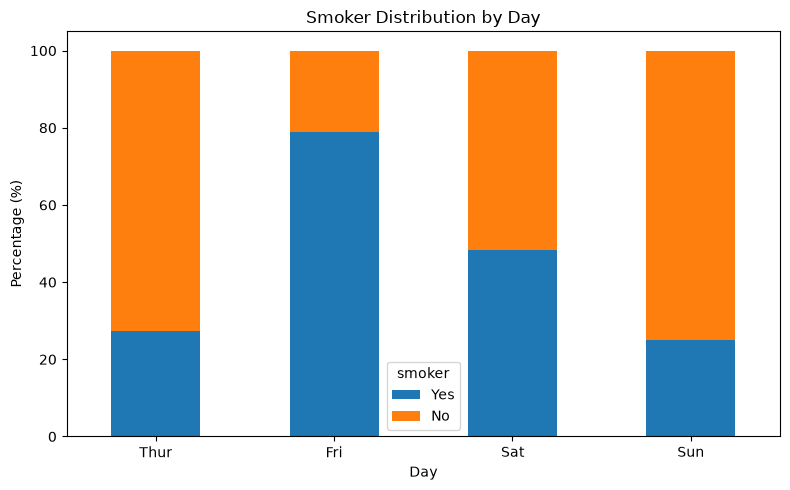

In [11]:
day_percentages = pd.crosstab(
    df["day"],
    df["smoker"],
    normalize="index"
) * 100

display(day_percentages.round(2))

day_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Smoker Distribution by Day")
plt.ylabel("Percentage (%)")
plt.xlabel("Day")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Conclusion

In this notebook, I performed categorical data analysis by identifying unique categories, calculating category frequencies and percentage distributions, and examining rare categories, cardinality, and category imbalance. I also analyzed relationships between categorical variables and the numerical target variable `tip` using group summaries and box plots. Cross-tabulation was used to examine relationships between two categorical variables.

These analyses help reveal category patterns, uncommon values, and differences between groups. The findings should be interpreted in context, and categories should not be removed or combined without a clear reason.